(who-gives-blood-in-march)=
# March blood-donation probabilities

The Hsin-Chu blood center has a list of people who have donated before and has to decide whom to ask for the March 2007 drive. The response is whether that person gave blood in March 2007. Recency is months since the last donation, frequency is how many times they have given, total donated volume is cubic centimetres donated in total, and time is months since the first donation.

The file is the UCI Blood Transfusion Service Center table, 748 donors, from `https://archive.ics.uci.edu/ml/machine-learning-databases/blood-transfusion/transfusion.data`. Yeh, Yang and Ting, Knowledge-Based Systems 22:363-368 (2009). The UCI file pads some integers with spaces; those spaces are stripped here. Total donated volume is exactly 250 cc times frequency, so it is the same fact as the donation count and is not a predictor.

The decision is which probability to put on the call list. About a quarter of the donors in the file gave in March 2007, so a constant base rate is the list that ignores the history. A logit and a probit are the two binary regressions a desk would fit. A Gaussian linear model is the baseline that can leave the unit interval. Boosting uses the same three columns. Steps are chosen on held-out donors, stratified by whether they gave.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the probability a past donor gives blood in March 2007 |
| **Observed response** | `donated`, 1 if they did and 0 otherwise |
| **Estimand** | held-out log loss and Brier score of that probability |
| **Units** | nats per donor; Brier score is a squared probability error |
| **Sampling unit** | one row is one past donor with the March 2007 donation indicator |
| **Dependence** | The working likelihood treats donor records as conditionally independent; no cluster adjustment is estimated. |
| **Split and tuning** | donors, stratified by the outcome; 20% choose steps, 20% held out, refit on the rest |
| **Information** | months since last donation, number of prior donations, months since the first donation |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a causal effect of calling, a donation volume, or a probability for someone who has never given |

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.linear_model import LogisticRegression

import mboostrs as mb

csv_path = Path("blood_donation.csv")
if not csv_path.exists():
    csv_path = Path("docs/book/case_studies/blood_donation.csv")
raw = pl.read_csv(csv_path, comment_prefix="#")
monetary_gap = int((raw["monetary_cc"] - 250 * raw["frequency"]).abs().max())
frame = raw.with_columns(
    pl.col("donated").cast(pl.Float64),
    pl.col("recency_months").cast(pl.Float64),
    pl.col("frequency").cast(pl.Float64),
    pl.col("time_months").cast(pl.Float64),
)
formula = "donated ~ recency_months + frequency + time_months"
predictors = ["recency_months", "frequency", "time_months"]

rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for flag in (0.0, 1.0):
    ids = indexed.filter(pl.col("donated") == flag)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.20 * n))
    n_valid = int(round(0.20 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
print(
    f"{frame.height} donors, {int(frame['donated'].sum())} gave in March 2007; "
    f"{train.height} to fit the path, {valid.height} to choose steps, "
    f"{fit_rows.height} refit, {test.height} held out; monetary gap {monetary_gap} cc"
)


748 donors, 178 gave in March 2007; 448 to fit the path, 150 to choose steps, 598 refit, 150 held out; monetary gap 0 cc


In [2]:
def columns_of(data):
    return {name: data[name].to_numpy() for name in data.columns}


def log_loss(y, probability):
    p = np.clip(np.asarray(probability, dtype=float), 1e-6, 1.0 - 1e-6)
    y = np.asarray(y, dtype=float)
    return float(-np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p)))


def brier(y, probability):
    return float(np.mean((np.asarray(probability, dtype=float) - np.asarray(y, dtype=float)) ** 2))


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    logit = smf.logit(formula, columns_of(fit_rows)).fit(disp=False)
    probit = smf.probit(formula, columns_of(fit_rows)).fit(disp=False)
    ols = smf.ols(formula, columns_of(fit_rows)).fit()
    sklearn_logit = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=500)
    sklearn_logit.fit(fit_rows.select(predictors).to_numpy(), fit_rows["donated"].to_numpy())

y_test = test["donated"].to_numpy()
logit_p = np.asarray(logit.predict(columns_of(test)), dtype=float)
probit_p = np.asarray(probit.predict(columns_of(test)), dtype=float)
sklearn_p = sklearn_logit.predict_proba(test.select(predictors).to_numpy())[:, 1]
ols_mu = np.asarray(ols.predict(columns_of(test)), dtype=float)
base_rate = float(fit_rows["donated"].mean())
logit_converged = bool(logit.mle_retvals.get("converged"))
probit_converged = bool(probit.mle_retvals.get("converged"))


In [3]:
def choose_mstop(kind, cap):
    family = mb.Binomial() if kind == "binomial" else mb.Gaussian()
    path = mb.glmboost(formula, train, family=family, control=mb.boost_control(cap, 0.1))
    y_valid = valid["donated"].to_numpy()
    best_step, best_score = None, np.inf
    for step in range(10, cap + 1, 10):
        pred = np.asarray(path.with_mstop(step).predict(valid, type="response"), dtype=float).ravel()
        score = log_loss(y_valid, pred)
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap


boosted = {}
for label, kind in (("mboostrs glmboost Binomial", "binomial"), ("mboostrs glmboost Gaussian", "gaussian")):
    step, score, at_cap = choose_mstop(kind, 400)
    family = mb.Binomial() if kind == "binomial" else mb.Gaussian()
    fitted = mb.glmboost(formula, fit_rows, family=family, control=mb.boost_control(step, 0.1))
    boosted[label] = {
        "kind": kind,
        "mstop": step,
        "at_cap": at_cap,
        "fit": fitted,
        "pred": np.asarray(fitted.predict(test, type="response"), dtype=float).ravel(),
    }


In [4]:
rows = []


def add(method, probability, mstop=None, at_cap=None, note=""):
    probability = np.asarray(probability, dtype=float).ravel()
    rows.append({
        "method": method,
        "log_loss": log_loss(y_test, probability),
        "brier": brier(y_test, probability),
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add("training base rate", np.full(len(y_test), base_rate), note=f"prevalence {base_rate:.3f}")
add("statsmodels logit", logit_p, note=f"converged {logit_converged}")
add("statsmodels probit", probit_p, note=f"converged {probit_converged}")
add("sklearn LogisticRegression", sklearn_p, note="no penalty")
add(
    "mboostrs glmboost Binomial",
    boosted["mboostrs glmboost Binomial"]["pred"],
    boosted["mboostrs glmboost Binomial"]["mstop"],
    boosted["mboostrs glmboost Binomial"]["at_cap"],
    note="",
)
gauss = boosted["mboostrs glmboost Gaussian"]["pred"]
add(
    "mboostrs glmboost Gaussian",
    gauss,
    boosted["mboostrs glmboost Gaussian"]["mstop"],
    boosted["mboostrs glmboost Gaussian"]["at_cap"],
    note=f"outside [0, 1]: {float(((gauss < 0) | (gauss > 1)).mean()):.3f}",
)
summary = pl.DataFrame(rows).sort("log_loss")
display(summary)


method,log_loss,brier,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""sklearn LogisticRegression""",0.450284,0.144676,null,null,"""no penalty"""
"""statsmodels logit""",0.450284,0.144676,null,null,"""converged True"""
"""statsmodels probit""",0.452975,0.145572,null,null,"""converged True"""
"""mboostrs glmboost Binomial""",0.455246,0.146141,190,false,""""""
"""mboostrs glmboost Gaussian""",0.471555,0.152209,90,false,"""outside [0, 1]: 0.007"""
"""training base rate""",0.551098,0.182406,null,null,"""prevalence 0.237"""


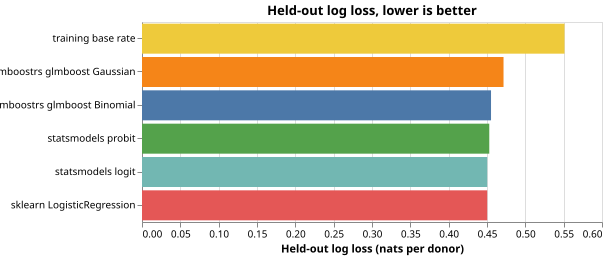

In [5]:
alt.Chart(summary).mark_bar().encode(
    x=alt.X("log_loss:Q", title="Held-out log loss (nats per donor)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=460,
    height=200,
    title="Held-out log loss, lower is better",
)


## Results and interpretation

Publish the logit probability. On the held-out donors its log loss is {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels logit')['log_loss'][0]):.3f}"` nats and its Brier score is {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels logit')['brier'][0]):.3f}"`. The training base rate scores {eval}`f"{float(summary.filter(pl.col('method')=='training base rate')['log_loss'][0]):.3f}"`. The history is worth that gap. The probability model captures that gap; calling at random, or calling nobody, does not.

The probit is {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels probit')['log_loss'][0]):.3f}"` nats and the unpenalized (no regularization term) sklearn logit is {eval}`f"{float(summary.filter(pl.col('method')=='sklearn LogisticRegression')['log_loss'][0]):.3f}"`. The binomial boost, {eval}`str(int(summary.filter(pl.col('method')=='mboostrs glmboost Binomial')['mstop'][0]))` steps, is {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Binomial')['log_loss'][0]):.3f}"`. None of these is a reason to leave the closed-form logit. The coefficient on months since the last donation is {eval}`f"{float(logit.params['recency_months']):.3f}"`, and on the number of prior donations it is {eval}`f"{float(logit.params['frequency']):.3f}"`. A longer gap lowers the probability. More past donations raise it. Months since the first donation is {eval}`f"{float(logit.params['time_months']):.3f}"`: once recency and frequency are in the model, a long history is not itself a reason to call.

The Gaussian boost scores {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['log_loss'][0]):.3f}"` only after the log loss clips its mean into (0, 1). The unclipped mean leaves the unit interval for {eval}`f"{float(((gauss < 0) | (gauss > 1)).mean()):.1%}"` of the held-out donors. Do not put that number on the call list.

Do not add total cubic centimetres. It matches 250 times the donation count on every row (the largest gap is {eval}`str(monetary_gap)` cc). This is the chance a past donor gives in March 2007, not a volume and not a donor the center has never seen.


In [6]:
binomial = boosted["mboostrs glmboost Binomial"]["fit"]
link = np.asarray(binomial.predict(type="link"), dtype=float).ravel()
response = np.asarray(binomial.predict(type="response"), dtype=float).ravel()
half_logit_gap = float(np.max(np.abs(response - 1.0 / (1.0 + np.exp(-2.0 * link)))))
y_fit = fit_rows["donated"].to_numpy()
bernoulli = float(np.sum(
    y_fit * np.log(np.clip(response, 1e-12, 1.0))
    + (1.0 - y_fit) * np.log(np.clip(1.0 - response, 1e-12, 1.0))
))
binomial_ll_gap = abs(float(binomial.logLik()) - bernoulli)
print("half-logit gap", half_logit_gap)
print("logLik gap", binomial_ll_gap)


half-logit gap 0.0
logLik gap 5.684341886080802e-14


## API behavior and limitations

`Binomial` `predict` with no `type` is not the probability. It is half the log-odds, because the family's link is scaled by 2. `type="response"` is `1 / (1 + exp(-2 f))`, and on this fit that matches the response to {eval}`f"{half_logit_gap:.1e}"`. A caller who applies the inverse logit (the logistic function) to the link once, as a logit would, squares the odds. `logLik()` matches the Bernoulli likelihood of `type="response"` to {eval}`f"{binomial_ll_gap:.1e}"`.

The Gaussian row is scored by clipping the mean into (0, 1) before the log loss. The note in the table is the share of means that were outside that interval before clipping. Logit and probit both report converged.
